# Bagian 3 – Evaluasi & Demo (Raniyol)
**Tugas JST: Klasifikasi Jenis Sampah dengan CNN (VGG16 Transfer Learning)**

Notebook ini mengerjakan tugas Raniyol: akurasi test, precision/recall/F1 per kelas, confusion matrix, analisis salah tebak, dan demo prediksi gambar baru. Hasilnya langsung menjadi bahan **slide 11 dan 12**.

**Sebelum menjalankan, pastikan di Google Drive-mu ada:**
1. `Tugas_JST/data_split.zip` dari Azmi
2. `hasil_acang/model/vgg16_sampah_final.keras` dan `class_names.json` dari Acang
3. Folder `hasil_raniyol/demo_images/` berisi 3–5 foto sampah baru (**bukan** dari dataset TrashNet). Boleh dikosongkan dulu; sel demo akan memberi tahu kalau masih kosong.

Kalau folder dari teman belum ada di Drive-mu: klik kanan folder > *Organize* > *Add shortcut* > *My Drive*.

> Jalankan di Colab: **Runtime → Run all**. GPU tidak wajib untuk evaluasi 380 gambar.

In [1]:
import os, zipfile, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from google.colab import drive

drive.mount("/content/drive")

# ====== ATUR DI SINI ======
import glob
ZIP_DRIVE = "/content/drive/MyDrive/COOLYEAH & LIFE/SMT 7 KING/JST/Tugas_JST/data_split.zip"
if not os.path.exists(ZIP_DRIVE):
    ZIP_DRIVE = (glob.glob("/content/drive/MyDrive/*/data_split.zip") or [ZIP_DRIVE])[0]
MODEL_PATH = "/content/drive/MyDrive/COOLYEAH & LIFE/SMT 7 KING/JST/hasil_acang/model/vgg16_sampah_final.keras"
CLASS_JSON = "/content/drive/MyDrive/COOLYEAH & LIFE/SMT 7 KING/JST/hasil_acang/model/class_names.json"
PREPROCESS_IN_MODEL = False   # model Acang TIDAK berisi preprocess_input; normalisasi dilakukan di pipeline data
OUT_DIR  = "/content/drive/MyDrive/COOLYEAH & LIFE/SMT 7 KING/JST/hasil_raniyol"        # folder hasil milikmu sendiri
DEMO_DIR = f"{OUT_DIR}/demo_images"
EXPECTED_ACC = 0.85   # akurasi test yang dilaporkan Acang; hasilmu harus sama (cek sanity)
os.makedirs(DEMO_DIR, exist_ok=True)
# ==========================

SEED = 42; random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE, BATCH_SIZE = (224, 224), 32
CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]   # urutan alfabet, sama seperti notebook Azmi
LABEL_ID = {"cardboard":"Kardus","glass":"Kaca","metal":"Logam","paper":"Kertas","plastic":"Plastik","trash":"Residu"}
NAMES_ID = [LABEL_ID[c] for c in CLASSES]
os.makedirs("figures_eval", exist_ok=True)

Mounted at /content/drive


## 1. Muat data test (dari Azmi) dan model (dari Acang)

In [ ]:
if not os.path.exists("data_split/test"):
    with zipfile.ZipFile(ZIP_DRIVE) as z:
        z.extractall("data_split")

test_raw = tf.keras.utils.image_dataset_from_directory(
    "data_split/test", labels="inferred", label_mode="categorical", class_names=CLASSES,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False)          # shuffle=False WAJIB supaya urutan label cocok
test_paths = test_raw.file_paths
preprocess = tf.keras.applications.vgg16.preprocess_input
test_ds = test_raw if PREPROCESS_IN_MODEL else test_raw.map(lambda x, y: (preprocess(x), y)).prefetch(tf.data.AUTOTUNE)

import json
assert json.load(open(CLASS_JSON))["classes"] == CLASSES, "Urutan kelas beda dengan model Acang!"
model = tf.keras.models.load_model(MODEL_PATH)
print("Jumlah gambar test:", len(test_paths))
print("Output model:", model.output_shape)   # harus (None, 6)

Found 380 files belonging to 6 classes.
Jumlah gambar test: 380
Output model: (None, 6)


## 2. Metrik evaluasi pada data test
Data test **tidak pernah dipakai** untuk training maupun EarlyStopping, jadi ini estimasi performa yang jujur pada data baru.

In [ ]:
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_raw])
probs  = model.predict(test_ds, verbose=0)
y_pred = probs.argmax(axis=1)
conf   = probs.max(axis=1)

acc = accuracy_score(y_true, y_pred)
print(f"Akurasi test: {acc:.4f} ({acc*100:.2f}%)  ->  {(y_true==y_pred).sum()} benar dari {len(y_true)} gambar")
print("Sanity check vs Acang:", "OK" if abs(acc-EXPECTED_ACC) < 0.01 else "BEDA! cek urutan data / preprocessing", "\n")
print(classification_report(y_true, y_pred, target_names=NAMES_ID, digits=3))

p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=range(6), zero_division=0)
tabel = pd.DataFrame({"Kelas": NAMES_ID, "Precision": p.round(3), "Recall": r.round(3), "F1-score": f.round(3), "Jumlah data": s})
macro = tabel[["Precision","Recall","F1-score"]].mean().round(3)
print("Rata-rata macro  :", macro.to_dict())
tabel.to_csv("figures_eval/tabel_metrik.csv", index=False)
tabel

Akurasi test: 0.8500 (85.00%)  ->  323 benar dari 380 gambar
Sanity check vs Acang: OK 

              precision    recall  f1-score   support

      Kardus      0.903     0.933     0.918        60
        Kaca      0.819     0.776     0.797        76
       Logam      0.734     0.935     0.823        62
      Kertas      0.940     0.876     0.907        89
     Plastik      0.919     0.781     0.844        73
      Residu      0.682     0.750     0.714        20

    accuracy                          0.850       380
   macro avg      0.833     0.842     0.834       380
weighted avg      0.859     0.850     0.851       380

Rata-rata macro  : {'Precision': 0.833, 'Recall': 0.842, 'F1-score': 0.834}


,Kelas,Precision,Recall,F1-score,Jumlah data
0,Kardus,0.903,0.933,0.918,60
1,Kaca,0.819,0.776,0.797,76
2,Logam,0.734,0.935,0.823,62
3,Kertas,0.940,0.876,0.907,89
4,Plastik,0.919,0.781,0.844,73
5,Residu,0.682,0.750,0.714,20


## 3. Confusion matrix

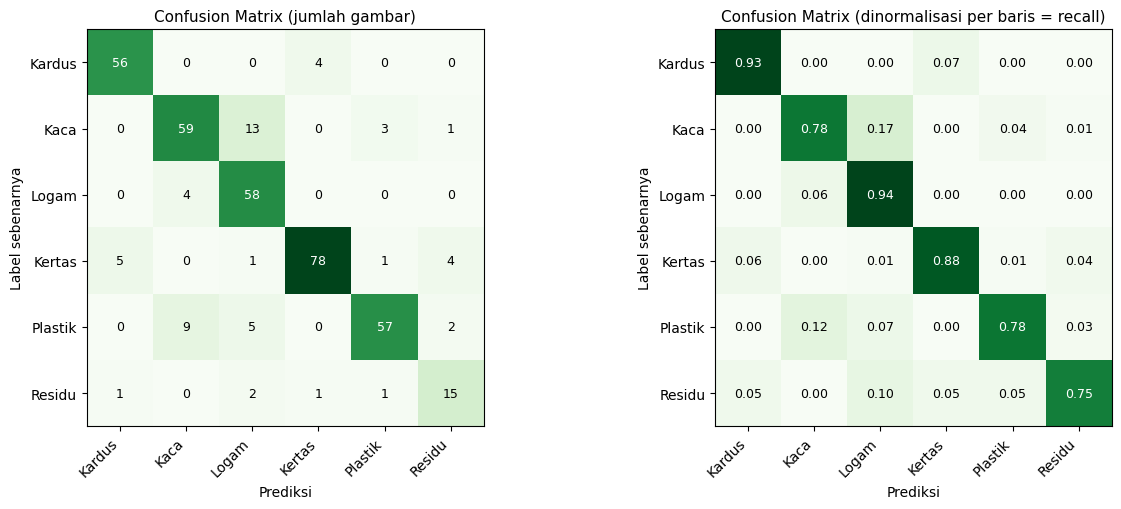

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(6))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, data, title, fmt in [(axes[0], cm, "Confusion Matrix (jumlah gambar)", "d"),
                             (axes[1], cm_norm, "Confusion Matrix (dinormalisasi per baris = recall)", ".2f")]:
    im = ax.imshow(data, cmap="Greens")
    ax.set_xticks(range(6)); ax.set_xticklabels(NAMES_ID, rotation=45, ha="right")
    ax.set_yticks(range(6)); ax.set_yticklabels(NAMES_ID)
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Label sebenarnya"); ax.set_title(title, fontsize=11)
    for i in range(6):
        for j in range(6):
            v = data[i, j]
            ax.text(j, i, format(v, fmt), ha="center", va="center",
                    color="white" if v > data.max()*0.55 else "black", fontsize=9)
plt.tight_layout(); plt.savefig("figures_eval/confusion_matrix.png", dpi=200); plt.show()

## 4. Analisis kesalahan: kelas mana yang sering tertukar?

Pasangan salah tebak terbanyak (sebenarnya -> diprediksi):
  Kaca     -> Logam   : 13 gambar
  Plastik  -> Kaca    : 9 gambar
  Kertas   -> Kardus  : 5 gambar
  Plastik  -> Logam   : 5 gambar
  Kardus   -> Kertas  : 4 gambar

Total salah tebak: 57 dari 380
Rata-rata confidence saat BENAR: 0.95 | saat SALAH: 0.77


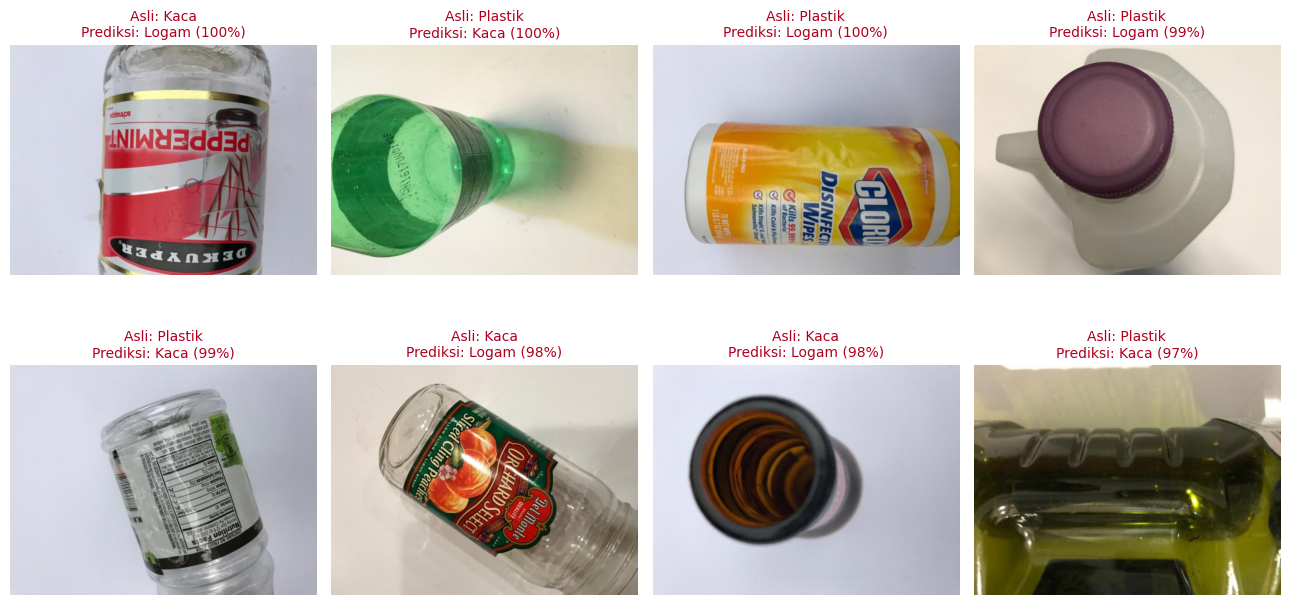

In [ ]:
pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(6) for j in range(6) if i != j and cm[i, j] > 0]
pairs.sort(key=lambda t: -t[2])
print("Pasangan salah tebak terbanyak (sebenarnya -> diprediksi):")
for a, b, n in pairs[:5]:
    print(f"  {LABEL_ID[a]:8s} -> {LABEL_ID[b]:8s}: {n} gambar")

salah = np.where(y_true != y_pred)[0]
print(f"\nTotal salah tebak: {len(salah)} dari {len(y_true)}")
print(f"Rata-rata confidence saat BENAR: {conf[y_true==y_pred].mean():.2f} | saat SALAH: {conf[salah].mean():.2f}")

# tampilkan 8 salah tebak dengan keyakinan tertinggi (kesalahan yang paling 'meyakinkan')
top = salah[np.argsort(-conf[salah])][:8]
if len(top):
    fig, axes = plt.subplots(2, 4, figsize=(13, 7))
    for ax, idx in zip(axes.ravel(), top):
        ax.imshow(plt.imread(test_paths[idx])); ax.axis("off")
        ax.set_title(f"Asli: {NAMES_ID[y_true[idx]]}\nPrediksi: {NAMES_ID[y_pred[idx]]} ({conf[idx]:.0%})", fontsize=10, color="#B00020")
    for ax in axes.ravel()[len(top):]: ax.axis("off")
    plt.tight_layout(); plt.savefig("figures_eval/contoh_salah_tebak.png", dpi=200); plt.show()

## 5. Demo prediksi gambar baru
Taruh 3–5 foto sampah sungguhan di `MyDrive/Tugas_JST/demo_images/` (misalnya botol plastik, kaleng, kardus, kertas, pecahan kaca). Foto sebaiknya **bukan** dari TrashNet.

Gambar demo: ['images (4).jpg', 'images (5).jpg', 'images10jpg.jpg', 'images6.jpg', 'images7.jpg', 'images8.jpg', 'images9.jpg']


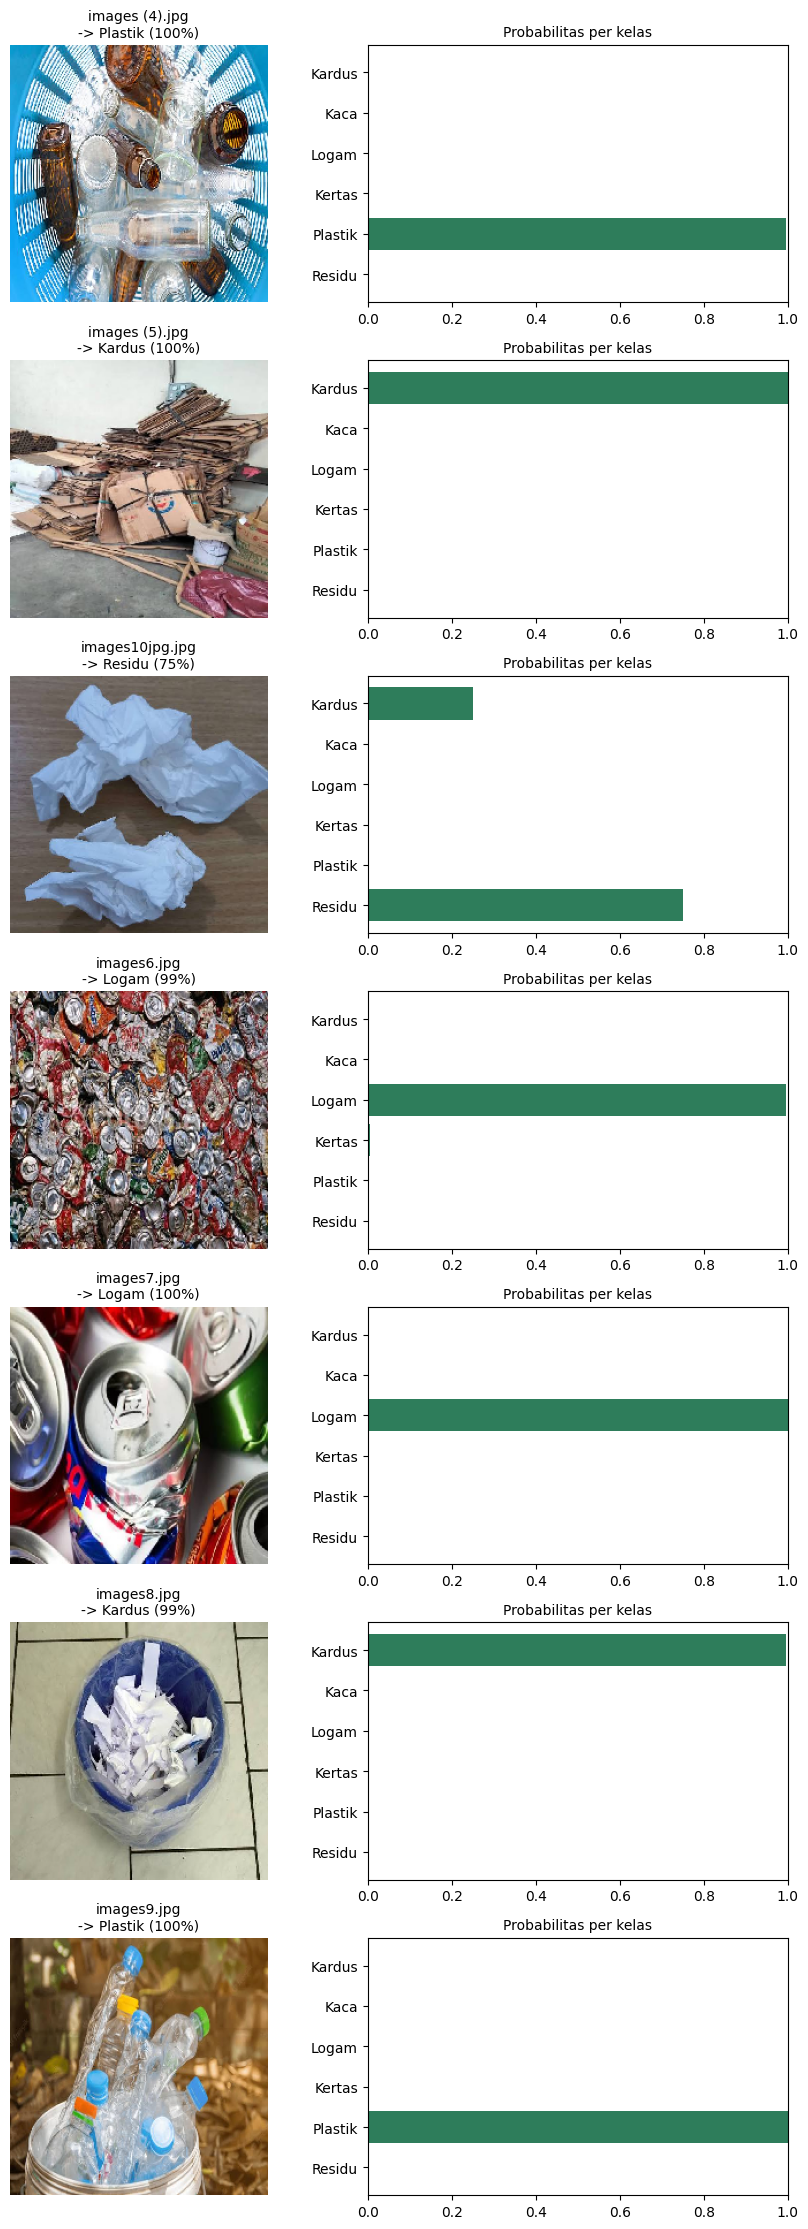

,File,Prediksi,Confidence,Top-2
0,images (4).jpg,Plastik,99.6%,Kaca (0.2%)
1,images (5).jpg,Kardus,100.0%,Logam (0.0%)
2,images10jpg.jpg,Residu,75.0%,Kardus (25.0%)
3,images6.jpg,Logam,99.5%,Kertas (0.5%)
4,images7.jpg,Logam,100.0%,Plastik (0.0%)
5,images8.jpg,Kardus,99.5%,Logam (0.4%)
6,images9.jpg,Plastik,100.0%,Residu (0.0%)


In [ ]:
files = sorted(f for f in os.listdir(DEMO_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp")))
print("Gambar demo:", files)
if not files:
    raise SystemExit(f"Folder demo masih kosong. Upload 3-5 foto ke {DEMO_DIR}, lalu jalankan ulang sel ini.")

fig, axes = plt.subplots(len(files), 2, figsize=(9, 3.2*len(files)), squeeze=False)
rows = []
for k, fn in enumerate(files):
    img = tf.keras.utils.load_img(os.path.join(DEMO_DIR, fn), target_size=IMG_SIZE)
    x = tf.keras.utils.img_to_array(img)[None]
    x = x if PREPROCESS_IN_MODEL else preprocess(x.copy())
    pr = model.predict(x, verbose=0)[0]
    top3 = pr.argsort()[::-1][:3]
    rows.append({"File": fn, "Prediksi": NAMES_ID[top3[0]], "Confidence": f"{pr[top3[0]]:.1%}",
                 "Top-2": f"{NAMES_ID[top3[1]]} ({pr[top3[1]]:.1%})"})
    axes[k, 0].imshow(img); axes[k, 0].axis("off")
    axes[k, 0].set_title(f"{fn}\n-> {NAMES_ID[top3[0]]} ({pr[top3[0]]:.0%})", fontsize=10)
    axes[k, 1].barh(NAMES_ID[::-1], pr[::-1], color="#2E7D5B"); axes[k, 1].set_xlim(0, 1)
    axes[k, 1].set_title("Probabilitas per kelas", fontsize=10)
plt.tight_layout(); plt.savefig("figures_eval/demo_prediksi.png", dpi=200); plt.show()
pd.DataFrame(rows)

## 6. Ringkasan angka untuk slide & simpan ke Drive

In [ ]:
import shutil
print("="*50)
print(f"Akurasi test        : {acc*100:.2f}%")
print(f"Macro precision/rec/F1: {macro['Precision']} / {macro['Recall']} / {macro['F1-score']}")
print(f"Kelas F1 terendah   : {tabel.loc[tabel['F1-score'].idxmin(),'Kelas']} ({tabel['F1-score'].min():.3f})")
print(f"Kelas F1 tertinggi  : {tabel.loc[tabel['F1-score'].idxmax(),'Kelas']} ({tabel['F1-score'].max():.3f})")
print(f"Jumlah salah tebak  : {len(salah)} dari {len(y_true)}")
print("="*50)
shutil.copytree("figures_eval", f"{OUT_DIR}/figures_eval", dirs_exist_ok=True)
print("Tersimpan di", f"{OUT_DIR}/figures_eval", os.listdir(f"{OUT_DIR}/figures_eval"))

Akurasi test        : 85.00%
Macro precision/rec/F1: 0.833 / 0.842 / 0.834
Kelas F1 terendah   : Residu (0.714)
Kelas F1 tertinggi  : Kardus (0.918)
Jumlah salah tebak  : 57 dari 380
Tersimpan di /content/drive/MyDrive/COOLYEAH & LIFE/SMT 7 KING/JST/hasil_raniyol/figures_eval ['tabel_metrik.csv', 'confusion_matrix.png', 'contoh_salah_tebak.png', 'demo_prediksi.png']
